In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.multioutput import MultiOutputRegressor

from xgboost import XGBRegressor

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

sns.set_style("whitegrid")


In [2]:
df = pd.read_csv("gold_2007_to_present.csv")

df = df.rename(columns={df.columns[0]: "Date"})
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df = df.dropna(subset=["Date"])

for col in df.columns:
    if col != "Date":
        df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.ffill().bfill()
df = df.set_index("Date")

print(df.head())


                 Close        High         Low        Open  Volume
Date                                                              
2007-01-02  635.200012  635.200012  635.200012  635.200012      17
2007-01-03  627.099976  640.400024  628.500000  640.400024      38
2007-01-04  623.900024  624.500000  624.500000  624.500000       4
2007-01-05  604.900024  623.700012  617.299988  623.700012     531
2007-01-08  607.500000  607.500000  607.500000  607.500000    1000


C:\Users\ASUS\AppData\Local\Temp\ipykernel_31076\3208892335.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Date"] = pd.to_datetime(df["Date"], errors="coerce")


In [3]:
df["Prev_Close"]  = df["Close"].shift(1)
df["Prev_High"]   = df["High"].shift(1)
df["Prev_Low"]    = df["Low"].shift(1)
df["Prev_Volume"] = df["Volume"].shift(1)

df["Today_Open"] = df["Open"]

df = df.dropna()


In [6]:
FEATURES = [
    "Today_Open",
    "Prev_Close",
    "Prev_High",
    "Prev_Low",
    "Prev_Volume"
]

TARGETS = ["High", "Low"]

X = df[FEATURES].values
y = df[TARGETS].values


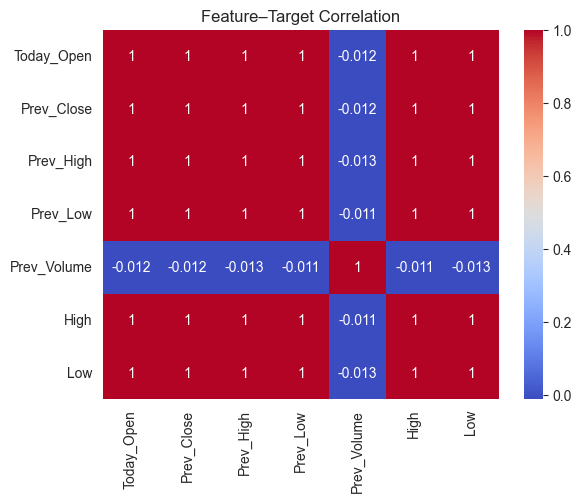

In [7]:
sns.heatmap(
    df[FEATURES + TARGETS].corr(),
    annot=True, cmap="coolwarm"
)
plt.title("Feature–Target Correlation")
plt.show()


In [8]:
split = int(len(df) * 0.85)

X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]


In [9]:
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_s = scaler_X.fit_transform(X_train)
X_test_s  = scaler_X.transform(X_test)

y_train_s = scaler_y.fit_transform(y_train)
y_test_s  = scaler_y.transform(y_test)


In [10]:
xgb = MultiOutputRegressor(
    XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="reg:squarederror"
    )
)

xgb.fit(X_train_s, y_train_s)


,estimator,"XGBRegressor(...ree=None, ...)"
,n_jobs,None
,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.9
,device,None
,early_stopping_rounds,None


In [11]:
pred_xgb = scaler_y.inverse_transform(
    xgb.predict(X_test_s)
)

print("XGBoost Performance")
print("MAE :", mean_absolute_error(y_test, pred_xgb))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred_xgb)))
print("R2  :", r2_score(y_test, pred_xgb))


XGBoost Performance
MAE : 551.5506214613325
RMSE: 807.5615020980099
R2  : -0.7320328467780737
